# Pertemuan 7 — Praktikum 2: FAISS

FAISS (*Facebook AI Similarity Search*) adalah pustaka ANN yang dikembangkan tim AI Research Meta untuk pencarian tetangga terdekat pada data berukuran sangat besar dan berdimensi tinggi. Berbeda dengan Annoy yang memakai pohon acak, FAISS menekankan efisiensi matematis melalui kuantisasi vektor dan pengelompokan data.

FAISS menyediakan beberapa jenis index. `IndexFlat` melakukan pencarian menyeluruh tanpa kompresi sehingga hasilnya selalu exact. `IVF` (*Inverted File Index*) membagi ruang vektor menjadi beberapa klaster dengan K-Means, sehingga pencarian hanya dilakukan pada klaster yang paling dekat dengan query. `PQ` (*Product Quantization*) memecah vektor berdimensi tinggi menjadi beberapa sub-vektor dan menggantinya dengan indeks centroid terdekat, sehingga kebutuhan memori jauh berkurang. Gabungan keduanya, `IVF + PQ`, menghasilkan pencarian yang cepat sekaligus hemat memori.

Sumber: [Praktikum 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-2) dan [FAISS](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/faiss).

## 1. Pemasangan pustaka

FAISS dipasang melalui paket `faiss-cpu`. Versi GPU tersedia melalui paket `faiss-gpu` bagi perangkat yang mendukung. Pada lingkungan yang dipakai laporan ini, FAISS sudah tersedia.

In [1]:
# Pemasangan sekali saja
# !pip install faiss-cpu
# !pip install faiss-gpu

import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Percobaan — Exact NN dibandingkan IVF + PQ

Percobaan memakai 1.000 titik acak dua dimensi. Query diletakkan di tengah ruang, yaitu pada koordinat (0,5; 0,5). Tiga tetangga terdekat dicari dengan `IndexFlatL2` yang bersifat exact dan dengan `IndexIVFPQ` yang bersifat approximate.

In [2]:
# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)  # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10  # jumlah cluster (inverted list)
m = 2       # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)  # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0036559104919433594
Waktu IVF+PQ: 0.0007901191711425781


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


## 3. Visualisasi hasil

Hasil kedua index digambarkan pada satu bidang. Bintang merah adalah query, lingkaran biru adalah hasil exact, dan tanda silang hijau adalah hasil IVF + PQ.

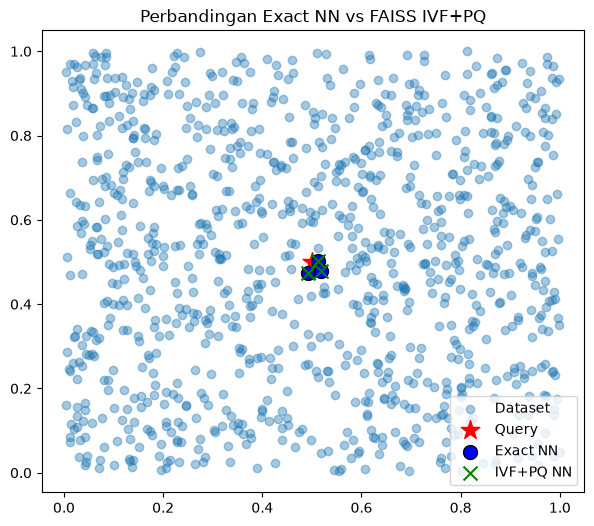

In [3]:
# 5. Visualisasi
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

Pada data 1.000 titik, hasil IVF + PQ masih sama dengan hasil exact. Kuantisasi baru mulai menimbulkan perbedaan ketika jumlah data dan dimensi bertambah, karena centroid yang mewakili setiap sub-vektor hanya mendekati nilai aslinya.

## 4. Tabel percobaan pengaruh metrik, jumlah data, dan dimensi

Percobaan dilanjutkan dengan memvariasikan metrik jarak (L2 dan Inner Product), jumlah data (1.000 dan 1.000.000), serta jumlah dimensi (2 dan 5). Pada FAISS, metrik L2 memakai `IndexFlatL2` dan `IndexIVFPQ`, sedangkan Inner Product memakai `IndexFlatIP` dengan `IndexIVFPQ` bermetrik Inner Product.

Nilai `m` pada *product quantization* harus membagi jumlah dimensi. Untuk data dua dimensi dipakai `m = 2`, sedangkan untuk data lima dimensi dipakai `m = 1`.

In [4]:
def uji_faiss(n_data, dim, metrik, nlist=10, k=3, seed=42):
    """Membandingkan IndexFlat (exact) dengan IndexIVFPQ (approximate)."""
    rng = np.random.default_rng(seed)
    data = (rng.random((n_data, dim))).astype('float32')
    titik = np.full((1, dim), 0.5, dtype='float32')
    m = dim if dim == 2 else 1

    if metrik == 'L2':
        index_flat = faiss.IndexFlatL2(dim)
        quantizer = faiss.IndexFlatL2(dim)
        metric_ivf = faiss.METRIC_L2
    else:
        index_flat = faiss.IndexFlatIP(dim)
        quantizer = faiss.IndexFlatIP(dim)
        metric_ivf = faiss.METRIC_INNER_PRODUCT

    index_flat.add(data)
    start = time.perf_counter()
    D_flat, I_flat = index_flat.search(titik, k)
    waktu_flat = (time.perf_counter() - start) * 1000

    index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8, metric_ivf)
    index_ivfpq.train(data)
    index_ivfpq.add(data)

    start = time.perf_counter()
    D_ivfpq, I_ivfpq = index_ivfpq.search(titik, k)
    waktu_ivfpq = (time.perf_counter() - start) * 1000

    return I_flat, I_ivfpq, waktu_flat, waktu_ivfpq


kombinasi = [
    ('L2', 1_000, 2),
    ('L2', 1_000_000, 2),
    ('L2', 1_000, 5),
    ('L2', 1_000_000, 5),
    ('Inner Product', 1_000, 2),
    ('Inner Product', 1_000_000, 2),
    ('Inner Product', 1_000, 5),
    ('Inner Product', 1_000_000, 5),
]

baris = []
for metrik, n_data, dim in kombinasi:
    I_flat, I_ivfpq, waktu_flat, waktu_ivfpq = uji_faiss(n_data, dim, metrik)
    baris.append({
        "Metrik": metrik,
        "Jumlah data": f"{n_data:,}".replace(",", "."),
        "Dimensi": dim,
        "Index Flat": str([int(x) for x in I_flat[0]]),
        "Index IVF+PQ": str([int(x) for x in I_ivfpq[0]]),
        "Waktu Flat (ms)": round(waktu_flat, 4),
        "Waktu IVF+PQ (ms)": round(waktu_ivfpq, 4),
    })

tabel_faiss = pd.DataFrame(baris)
display(tabel_faiss)

WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


,Metrik,Jumlah data,Dimensi,Index Flat,Index IVF+PQ,Waktu Flat (ms),Waktu IVF+PQ (ms)
0,L2,1.000,2,"[843, 634, 372]","[843, 634, 70]",0.0143,0.0171
1,L2,1.000.000,2,"[19638, 328755, 786703]","[328755, 786703, 19638]",1.7608,0.2691
2,L2,1.000,5,"[694, 534, 99]","[859, 671, 939]",0.0109,0.0158
3,L2,1.000.000,5,"[289393, 11237, 247737]","[21178, 21497, 36702]",1.2852,0.2106
4,Inner Product,1.000,2,"[936, 306, 263]","[936, 263, 306]",0.0542,0.0313
5,Inner Product,1.000.000,2,"[99583, 834419, 945126]","[936, 306, 263]",0.3220,0.2138
6,Inner Product,1.000,5,"[702, 182, 742]","[742, 640, 251]",0.0095,0.0149
7,Inner Product,1.000.000,5,"[656271, 701183, 741004]","[34186, 10956, 5913]",0.4809,0.2303


Tabel di atas memperlihatkan bahwa `IndexFlat` selalu mengembalikan hasil yang konsisten karena sifatnya yang exact, sedangkan `IndexIVFPQ` dapat menghasilkan indeks yang berbeda akibat kuantisasi. Perbedaan waktu antara keduanya belum terlihat pada data 1.000 titik karena jumlah data masih kecil, tetapi menjadi jelas pada data 1.000.000 titik. Pada data berukuran besar, IVF mempersempit ruang pencarian ke beberapa klaster saja sehingga jumlah perhitungan jarak berkurang jauh.

Percobaan dengan metrik Inner Product menunjukkan bahwa FAISS mendukung lebih dari satu ukuran kedekatan. Pada metrik ini nilai jarak yang besar justru menandakan kedekatan yang tinggi, berbeda dengan L2 di mana nilai kecil berarti dekat.

## Kesimpulan

FAISS menyediakan beberapa jenis index dengan karakteristik berbeda. `IndexFlat` menghasilkan pencarian exact tanpa kompresi, sedangkan `IVF + PQ` menghasilkan pencarian approximate yang jauh lebih hemat memori dan lebih cepat pada data besar. Pengaruh kuantisasi baru terasa pada data berukuran besar dan berdimensi tinggi, sementara pada data kecil hasil keduanya masih sama. FAISS juga mendukung metrik L2 dan Inner Product, sehingga dapat dipakai untuk pencarian kemiripan maupun *maximum inner product search*.